# Air Quality Analysis and PM2.5 Prediction Across Five Pakistani Cities
 |  **Tools:** Python, Pandas, Matplotlib, Seaborn, SciPy, Scikit-learn

---

## Project Overview

Air pollution is a serious public-health problem in Pakistan. This project studies **hourly air quality and weather data** from five major cities: **Lahore, Karachi, Islamabad, Peshawar and Quetta** (August 2021 to December 2024).

The project follows a simple data-analysis workflow:

1. Understand and clean the data
2. Explore the data and answer questions with charts
3. Build machine learning models to predict PM2.5
4. Write the findings, limitations and conclusion

## Objectives

- Compare air quality across the five cities
- Find out when (season, month, hour) pollution is highest
- Find which pollutants and weather variables are linked with PM2.5
- Build models to predict PM2.5 and check honestly how good they are

## Questions Answered in This Notebook

| No. | Question |
|-----|----------|
| Q1 | Which city has the highest average PM2.5? |
| Q2 | Which city has the worst AQI? |
| Q3 | How much does PM2.5 vary inside each city? |
| Q4 | Are the differences between cities statistically significant? |
| Q5 | Which season is the most polluted? |
| Q6 | How does PM2.5 change month by month? |
| Q7 | Is the air getting better or worse from year to year? |
| Q8 | At what time of day is PM2.5 highest? |
| Q9 | How often is PM2.5 above the WHO guideline? |
| Q10 | Which variables are most related to PM2.5? |
| Q11 | Does wind speed reduce PM2.5? |
| Q12 | Can we predict PM2.5, and which model works best? |
| Q13 | Which features matter most for prediction? |
| Q14 | How well does the model work on future data it has never seen? |

## About the Dataset

| Column | Meaning |
|--------|---------|
| `datetime` | Date and hour of the observation |
| `main.aqi` | Air Quality Index on a 1 to 5 scale (1 = best, 5 = worst) |
| `components.co`, `no`, `no2`, `o3`, `so2`, `nh3` | Concentrations of carbon monoxide, nitric oxide, nitrogen dioxide, ozone, sulphur dioxide and ammonia |
| `components.pm2_5`, `components.pm10` | Fine and coarse particulate matter (µg/m³) |
| `temperature_2m`, `relative_humidity_2m`, `dew_point_2m` | Temperature, humidity and dew point |
| `precipitation`, `surface_pressure` | Rainfall and air pressure |
| `wind_speed_10m`, `wind_direction_10m` | Wind speed and direction |
| `shortwave_radiation` | Sunlight (solar radiation) |
| `city` | City name |

**Target variable:** `PM2.5` is used as the target for prediction. PM2.5 particles are very small and can enter deep into the lungs, so it is one of the most harmful air pollutants.

## 1. Importing Libraries

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from scipy.stats import kruskal
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Loading the Dataset

In [2]:
# Load the dataset
df = pd.read_csv("pakistan_air_quality_weather_5cities.csv")

# First five rows
df.head()

,datetime,main.aqi,components.co,components.no,components.no2,components.o3,components.so2,components.pm2_5,components.pm10,components.nh3,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,surface_pressure,wind_speed_10m,wind_direction_10m,shortwave_radiation,city
0,2021-08-24 00:00:00,5,1014.71,0.00,17.14,35.76,6.44,59.59,66.81,5.95,28.1,80.0,24.3,0.0,976.6,6.2,170.0,0,Lahore
1,2021-08-24 01:00:00,5,1054.76,0.01,19.36,32.19,6.68,66.96,74.88,6.08,27.8,83.0,24.7,0.0,976.4,6.5,180.0,0,Lahore
2,2021-08-24 02:00:00,5,1295.09,1.40,30.16,22.89,8.70,79.88,89.90,7.73,27.4,87.0,25.0,0.0,976.2,5.4,180.0,0,Lahore
3,2021-08-24 03:00:00,5,1682.28,9.16,41.13,28.25,12.99,98.91,111.25,9.75,27.1,89.0,25.2,0.0,976.2,5.8,184.0,0,Lahore
4,2021-08-24 04:00:00,5,1321.79,4.81,32.56,91.55,27.90,89.59,97.95,7.28,26.9,91.0,25.2,0.0,976.1,6.1,183.0,0,Lahore


## 3. Dataset Understanding

In [3]:
# Rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null counts
print()
df.info()

Dataset Shape: (141201, 19)

Column Names:
['datetime', 'main.aqi', 'components.co', 'components.no', 'components.no2', 'components.o3', 'components.so2', 'components.pm2_5', 'components.pm10', 'components.nh3', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'surface_pressure', 'wind_speed_10m', 'wind_direction_10m', 'shortwave_radiation', 'city']

<class 'pandas.DataFrame'>
RangeIndex: 141201 entries, 0 to 141200
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   datetime              141201 non-null  str    
 1   main.aqi              141201 non-null  int64  
 2   components.co         141201 non-null  float64
 3   components.no         141201 non-null  float64
 4   components.no2        141201 non-null  float64
 5   components.o3         141201 non-null  float64
 6   components.so2        141201 non-null  float64
 7   components.pm2_5      141201 non-null  float64
 

In [4]:
# Summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
main.aqi,141201.0,4.146217,1.054651,1.000000,3.0000,5.000000,5.00,5.00
components.co,141201.0,2126.986929,2488.261208,150.200000,500.6800,1108.170000,2830.51,27771.00
components.no,141201.0,19.597396,47.193930,0.000000,0.0100,0.890000,12.52,686.65
components.no2,141201.0,49.668233,55.510398,0.340000,9.2500,28.790000,73.34,833.51
components.o3,141201.0,65.372871,64.424521,0.000000,8.2300,50.780000,100.14,709.53
components.so2,141201.0,12.946065,14.249410,0.160000,3.6100,8.340000,16.93,165.94
components.pm2_5,141201.0,113.284677,145.371328,0.500000,27.8100,58.720000,134.69,1965.05
components.pm10,141201.0,157.280027,168.946078,0.570000,55.6600,99.730000,189.90,2183.34
components.nh3,141201.0,23.672705,31.661461,0.000000,4.3700,11.780000,29.64,389.10
temperature_2m,141201.0,23.171848,8.613329,-9.035500,16.9000,24.700000,29.60,46.20


### Q1. How big is the dataset and what does it contain?

**Answer:** The dataset has **141,201 rows and 19 columns**. Each row is one hourly observation for one city. It contains 9 air-quality columns (AQI and 8 pollutants), 8 weather columns, the date-time and the city name. Each city has about 28,200 hourly records.

The summary statistics already show something important: the maximum PM2.5 value (1,965 µg/m³) is far above the average (113 µg/m³), so there are some extreme pollution episodes.

**Rename columns:** The original column names are long (`components.pm2_5`). We rename them so the code is easier to read.

In [5]:
# Give the columns shorter, easier names
df = df.rename(columns={
    'main.aqi': 'aqi',
    'components.co': 'co',
    'components.no': 'no',
    'components.no2': 'no2',
    'components.o3': 'o3',
    'components.so2': 'so2',
    'components.pm2_5': 'pm2_5',
    'components.pm10': 'pm10',
    'components.nh3': 'nh3',
    'temperature_2m': 'temperature',
    'relative_humidity_2m': 'humidity',
    'dew_point_2m': 'dew_point',
    'surface_pressure': 'pressure',
    'wind_speed_10m': 'wind_speed',
    'wind_direction_10m': 'wind_direction',
    'shortwave_radiation': 'solar_radiation'
})

df.columns.tolist()

['datetime',
 'aqi',
 'co',
 'no',
 'no2',
 'o3',
 'so2',
 'pm2_5',
 'pm10',
 'nh3',
 'temperature',
 'humidity',
 'dew_point',
 'precipitation',
 'pressure',
 'wind_speed',
 'wind_direction',
 'solar_radiation',
 'city']

## 4. Data Quality Check

### Are there any missing values or duplicate rows?

In [6]:
# Missing values in each column
df.isnull().sum()

datetime           0
aqi                0
co                 0
no                 0
no2                0
o3                 0
so2                0
pm2_5              0
pm10               0
nh3                0
temperature        0
humidity           0
dew_point          0
precipitation      0
pressure           0
wind_speed         0
wind_direction     0
solar_radiation    0
city               0
dtype: int64

In [7]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Number of rows per city
df['city'].value_counts()

Duplicate rows: 0


city
Lahore       28269
Islamabad    28245
Peshawar     28245
Karachi      28221
Quetta       28221
Name: count, dtype: int64

**Answer:** There are **no missing values** and **no duplicate rows**, and the five cities have almost the same number of records. No rows needed to be removed.

## 5. Fixing the Datetime Column

The `datetime` column was read as plain text. Let us look at some values.

In [8]:
# Look at some random datetime values
df['datetime'].sample(8, random_state=1)

38137    2022-10-13 04:00:00
73831    2023-08-27 14:00:00
34661    2022-05-19 08:00:00
43981    2023-06-19 16:00:00
82564    2024-08-31 14:00:00
91588         7/6/2022 13:00
64945    2022-08-15 07:00:00
58152    2021-11-01 06:00:00
Name: datetime, dtype: str

**Problem found:** The column contains **two different date styles**. Some rows look like `2022-10-13 04:00:00` (year first) and some look like `7/6/2022 13:00` (day first, so this is 7 June 2022).


In [9]:
# Rows written like 2021-08-24 contain a dash, rows like 24/08/2021 do not
has_dash = df['datetime'].str.contains('-')

# Convert each style separately
dates_1 = pd.to_datetime(df.loc[has_dash, 'datetime'])
dates_2 = pd.to_datetime(df.loc[~has_dash, 'datetime'], dayfirst=True, format='mixed')

# Put them back together in the original order
df['datetime'] = pd.concat([dates_1, dates_2]).sort_index()

df['datetime'].head()

0   2021-08-24 00:00:00
1   2021-08-24 01:00:00
2   2021-08-24 02:00:00
3   2021-08-24 03:00:00
4   2021-08-24 04:00:00
Name: datetime, dtype: datetime64[us]

In [10]:
# Check the time period covered for each city
df.groupby('city')['datetime'].agg(['min', 'max', 'count'])

,min,max,count
city,,,
Islamabad,2021-08-24,2024-12-01,28245
Karachi,2021-08-24,2024-12-01,28221
Lahore,2021-08-24,2024-12-01,28269
Peshawar,2021-08-24,2024-12-01,28245
Quetta,2021-08-24,2024-12-01,28221


**Answer:** After the fix, all five cities cover the same period: **24 August 2021 to 1 December 2024**. Because 2021 and 2024 are not complete years, we will be careful when comparing years.

## 6. Feature Engineering

We create new columns from the date-time: year, month, hour, day of week, weekend indicator and season. These help us find time patterns in pollution.

In [11]:
# Extract date and time parts
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek

# Weekend indicator (Saturday = 5, Sunday = 6)
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# Season feature
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['season'] = df['month'].apply(get_season)

# Check the new columns
df[['datetime', 'year', 'month', 'hour', 'day_of_week', 'is_weekend', 'season']].head()

,datetime,year,month,hour,day_of_week,is_weekend,season
0,2021-08-24 00:00:00,2021,8,0,1,0,Summer
1,2021-08-24 01:00:00,2021,8,1,1,0,Summer
2,2021-08-24 02:00:00,2021,8,2,1,0,Summer
3,2021-08-24 03:00:00,2021,8,3,1,0,Summer
4,2021-08-24 04:00:00,2021,8,4,1,0,Summer


## 7. Exploratory Data Analysis (EDA)

### Q1. Which city has the highest average PM2.5?

In [12]:
# Average PM2.5 by city
city_pm25 = df.groupby('city')['pm2_5'].mean().sort_values(ascending=False)
city_pm25.round(1)

city
Lahore       198.5
Peshawar     130.1
Islamabad    122.6
Karachi       81.5
Quetta        33.5
Name: pm2_5, dtype: float64

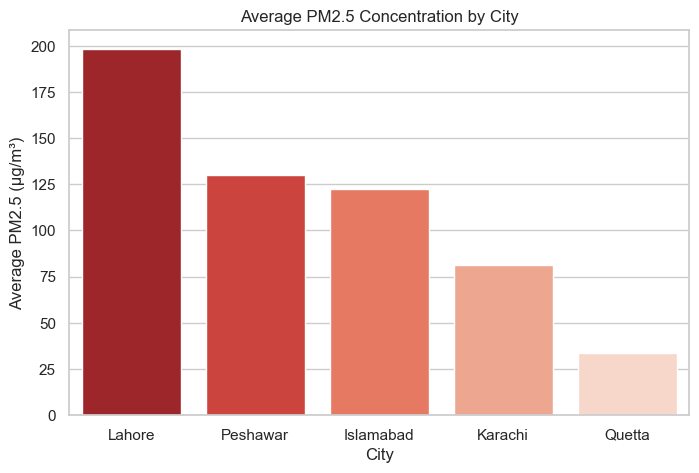

In [13]:
plt.figure(figsize=(8, 5))
sns.barplot(x=city_pm25.index, y=city_pm25.values, hue=city_pm25.index, palette='Reds_r', legend=False)

plt.title('Average PM2.5 Concentration by City')
plt.xlabel('City')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.show()

**Answer:** **Lahore** has the highest average PM2.5 (about **199 µg/m³**), followed by Peshawar (130), Islamabad (123) and Karachi (82). **Quetta** is the cleanest city (about **33 µg/m³**). Lahore's average is roughly **6 times higher** than Quetta's.

### Q2. Which city has the worst AQI?

In [14]:
# Average AQI by city
city_aqi = df.groupby('city')['aqi'].mean().sort_values(ascending=False)
print(city_aqi.round(2))

# Percentage of hours with the worst AQI level (5)
worst_pct = (df['aqi'] == 5).groupby(df['city']).mean() * 100
print("\nPercentage of hours with AQI = 5:")
print(worst_pct.sort_values(ascending=False).round(1))

city
Lahore       4.66
Islamabad    4.40
Peshawar     4.34
Karachi      3.89
Quetta       3.44
Name: aqi, dtype: float64

Percentage of hours with AQI = 5:
city
Lahore       77.7
Islamabad    63.5
Peshawar     60.1
Karachi      40.9
Quetta       20.0
Name: aqi, dtype: float64


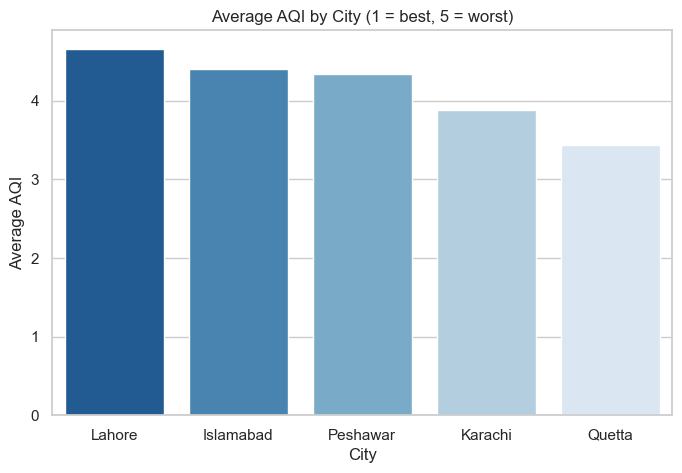

In [15]:
plt.figure(figsize=(8, 5))
sns.barplot(x=city_aqi.index, y=city_aqi.values, hue=city_aqi.index, palette='Blues_r', legend=False)

plt.title('Average AQI by City (1 = best, 5 = worst)')
plt.xlabel('City')
plt.ylabel('Average AQI')
plt.show()

**Answer:** **Lahore** also has the worst AQI (average 4.66 out of 5) and **Quetta** the best (3.44). In Lahore, the air quality was at the worst level (AQI = 5) in about **78% of all hours**, compared with 20% in Quetta.

The order of Islamabad and Peshawar is slightly different from the PM2.5 chart, because AQI combines several pollutants and not only PM2.5.

### Q3. How much does PM2.5 vary inside each city?

In [16]:
# Detailed PM2.5 statistics for each city
df.groupby('city')['pm2_5'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Islamabad,28245.0,122.6,117.4,2.8,42.4,82.0,160.8,1091.8
Karachi,28221.0,81.5,124.3,2.2,19.6,36.3,86.8,1965.0
Lahore,28269.0,198.5,198.9,3.1,65.8,121.5,261.4,1641.5
Peshawar,28245.0,130.1,145.5,2.3,38.1,78.8,163.0,1162.1
Quetta,28221.0,33.5,25.8,0.5,15.9,27.2,43.8,314.1


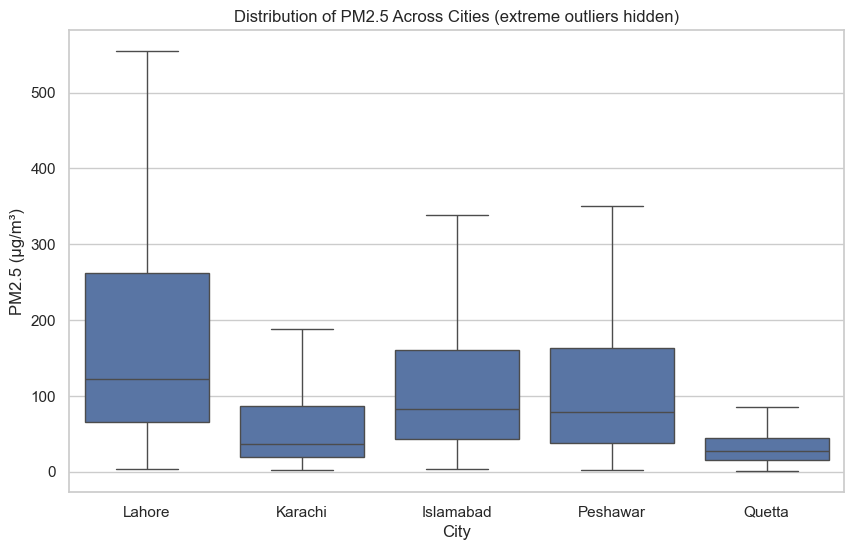

In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='city', y='pm2_5', showfliers=False)

plt.title('Distribution of PM2.5 Across Cities (extreme outliers hidden)')
plt.xlabel('City')
plt.ylabel('PM2.5 (µg/m³)')
plt.show()

**Answer:** Lahore has the highest typical level (median 121 µg/m³) and also the widest spread (standard deviation about 199). Quetta is not only the cleanest, it is also the most stable city.

In Karachi the **average (82) is much higher than the median (36)**. This means most hours are moderate, but a small number of extreme spikes (up to 1,965 µg/m³) pull the average up. Extreme values were kept in the data because they look like real pollution events, not errors.

### Q4. Are the differences between cities statistically significant?

We use the **Kruskal-Wallis test**. It is a simple test that compares more than two groups and does not need the data to follow a normal distribution (PM2.5 is clearly not normal).

- **Null hypothesis:** All cities have the same PM2.5 distribution.
- **Alternative:** At least one city is different.

In [18]:
# Kruskal-Wallis test: do the five cities have the same PM2.5 distribution?
groups = [group['pm2_5'] for name, group in df.groupby('city')]
stat, p_value = kruskal(*groups)

print("Test statistic:", round(stat, 1))
print("p-value smaller than 0.001:", p_value < 0.001)

Test statistic: 37386.6
p-value smaller than 0.001: True


**Answer:** The p-value is far below 0.001, so we **reject the null hypothesis**: PM2.5 levels are significantly different between the cities.

*Note:* hourly measurements that follow each other are not fully independent, so the p-value should not be over-interpreted. However, the differences between the cities are so large that the conclusion is clear.

### Q5. Which season is the most polluted?

In [19]:
# Average PM2.5 by season
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']

season_pm25 = df.groupby('season')['pm2_5'].mean().reindex(season_order)
season_pm25.round(1)

season
Winter    216.6
Spring     67.3
Summer     43.4
Autumn    126.9
Name: pm2_5, dtype: float64

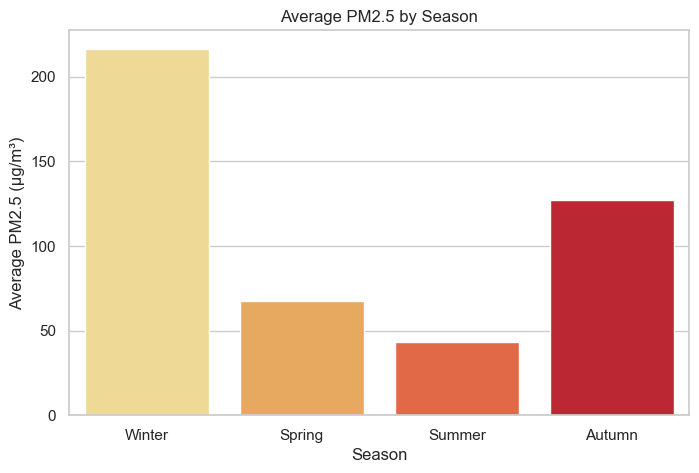

In [20]:
plt.figure(figsize=(8, 5))
sns.barplot(x=season_pm25.index, y=season_pm25.values, hue=season_pm25.index, palette='YlOrRd', legend=False)

plt.title('Average PM2.5 by Season')
plt.xlabel('Season')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.show()

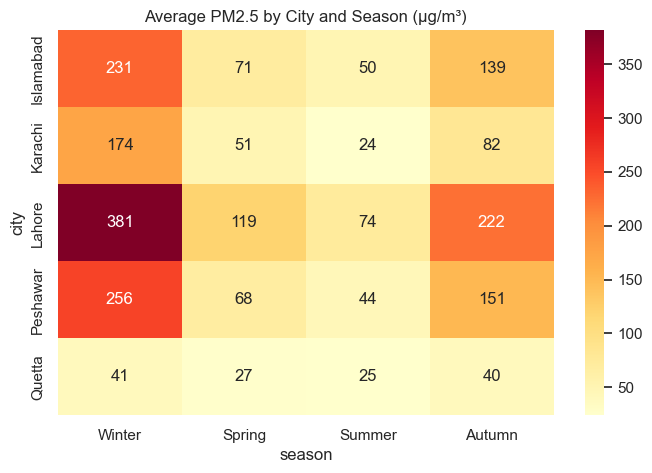

In [21]:
# Season and city together
season_city = df.pivot_table(values='pm2_5', index='city', columns='season', aggfunc='mean')
season_city = season_city[season_order]

plt.figure(figsize=(8, 5))
sns.heatmap(season_city, annot=True, fmt='.0f', cmap='YlOrRd')

plt.title('Average PM2.5 by City and Season (µg/m³)')
plt.show()

**Answer:** **Winter is by far the most polluted season** (average 217 µg/m³), followed by Autumn (127). Spring (67) and Summer (43) are much cleaner.

The heatmap shows that the winter problem is strongest in **Lahore (381 µg/m³)**, Peshawar (256) and Islamabad (231). Quetta stays low in every season (25 to 41 µg/m³).

### Q6. How does PM2.5 change month by month?

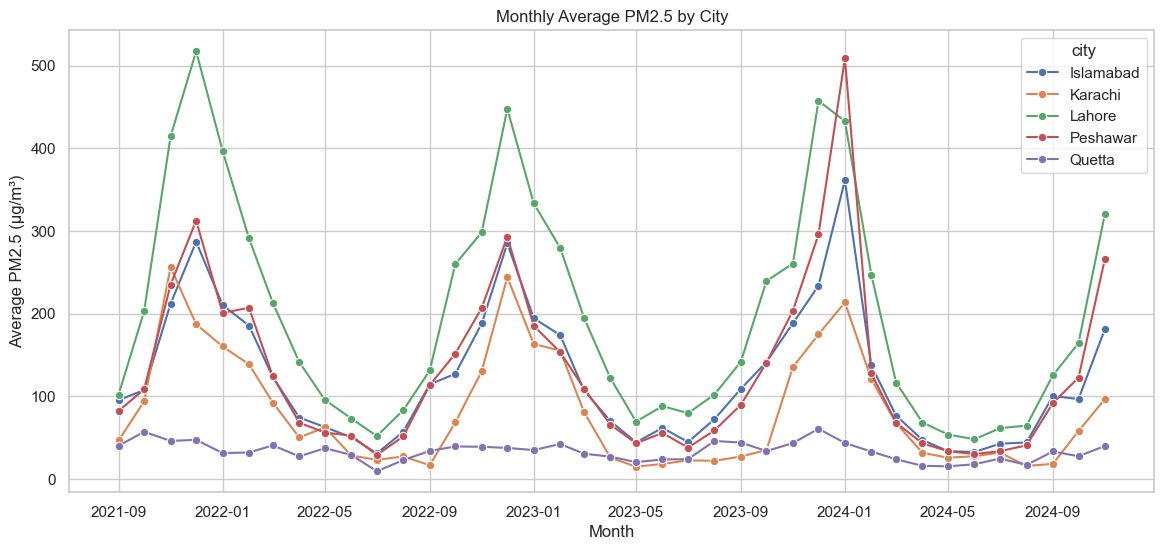

In [22]:
# The first and last months in the data are incomplete, so we leave them out here
monthly_df = df[(df['datetime'] >= '2021-09-01') & (df['datetime'] < '2024-12-01')].copy()

# Create a year-month column
monthly_df['year_month'] = monthly_df['datetime'].dt.to_period('M').dt.to_timestamp()

# Monthly average PM2.5 for each city
monthly_city = monthly_df.groupby(['year_month', 'city'])['pm2_5'].mean().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_city, x='year_month', y='pm2_5', hue='city', marker='o')

plt.title('Monthly Average PM2.5 by City')
plt.xlabel('Month')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.show()

**Answer:** The same pattern repeats every year: PM2.5 starts rising in **October**, peaks in **December and January**, and drops to its lowest level in **June and July**. Averaged over all cities, December is the worst month (259 µg/m³) and July is the best (37 µg/m³). Lahore shows the sharpest winter peaks. Quetta is almost flat.

### Q7. Is the air getting better or worse from year to year?

Because 2021 and 2024 are incomplete years, we compare only **January to November** of 2022, 2023 and 2024, so the comparison is fair.

In [23]:
# Compare the same months (Jan-Nov) of each full year
same_months = df[(df['month'] <= 11) & (df['year'] >= 2022)]

yearly = same_months.groupby(['year', 'city'])['pm2_5'].mean().unstack().round(1)
yearly

city,Islamabad,Karachi,Lahore,Peshawar,Quetta
year,,,,,
2022,110.8,72.2,184.4,114.0,31.4
2023,109.1,62.9,172.6,103.5,33.7
2024,104.9,64.5,154.5,124.3,26.7


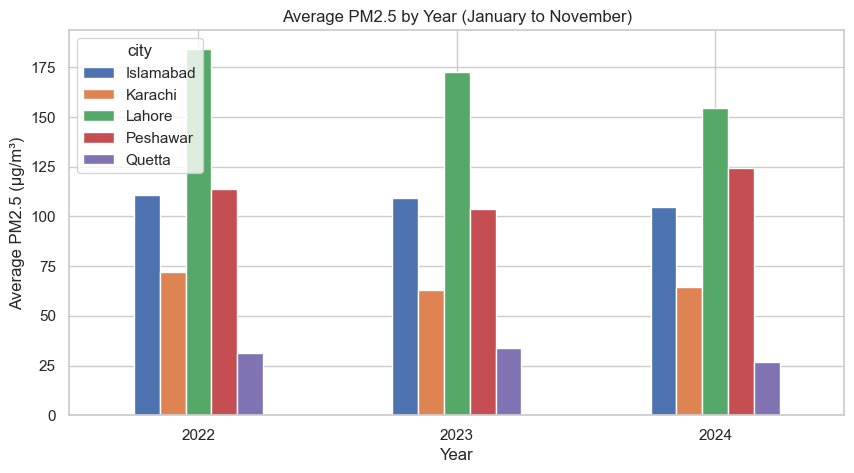

In [24]:
yearly.plot(kind='bar', figsize=(10, 5))

plt.title('Average PM2.5 by Year (January to November)')
plt.xlabel('Year')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.xticks(rotation=0)
plt.show()

**Answer:** The picture is **mixed**. Lahore shows a steady fall (184 to 172 to 154 µg/m³) and Islamabad a small fall. Karachi dropped from 2022 to 2023 and then stayed about the same. Peshawar went **up in 2024** (124), and Quetta fell in 2024.

With only three years of data we cannot say whether this is a real long-term trend or normal year-to-year variation. More years and weather information would be needed.

### Q8. At what time of day is PM2.5 highest?

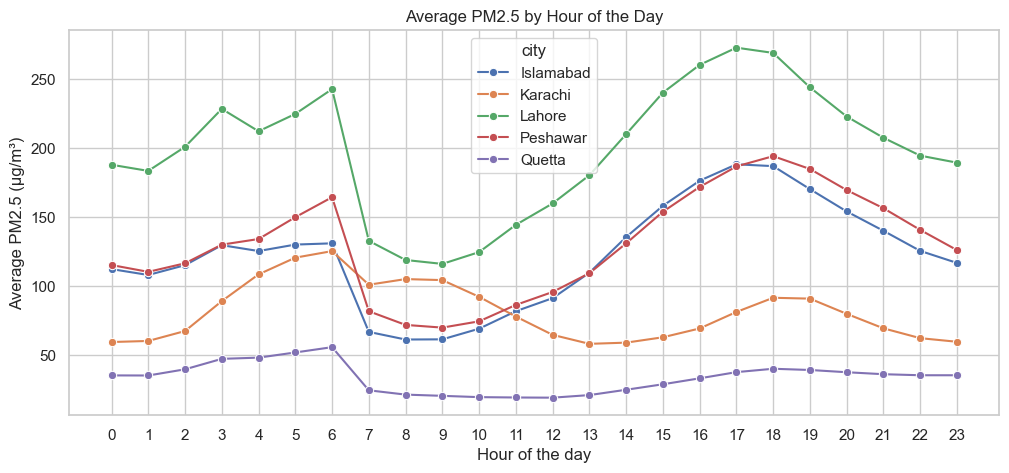

In [25]:
# Average PM2.5 for each hour of the day
hourly = df.groupby(['hour', 'city'])['pm2_5'].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=hourly, x='hour', y='pm2_5', hue='city', marker='o')

plt.title('Average PM2.5 by Hour of the Day')
plt.xlabel('Hour of the day')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.xticks(range(0, 24))
plt.show()

**Answer:** Most cities show the same daily pattern: PM2.5 is **lowest in the late morning (around 9:00)** and **highest in the evening (around 18:00)**, with another smaller rise in the early morning (around 6:00). This is consistent with traffic and cooking activity, and with the atmosphere trapping pollutants when it cools down at night. Quetta shows a much weaker daily pattern.

*Note:* the hour is shown as recorded in the dataset; the time zone is not given.

### Q9. How often is PM2.5 above the WHO guideline?

The World Health Organization recommends that the **24-hour average PM2.5 should not exceed 15 µg/m³**. We use this value as a simple reference line and count the share of hourly records above it. (Hourly values are not exactly the same as daily averages, so this is an approximate comparison.)

In [26]:
# WHO 24-hour guideline for PM2.5 is 15 µg/m³
who_limit = 15

above_who = (df['pm2_5'] > who_limit).groupby(df['city']).mean() * 100
above_who.sort_values(ascending=False).round(1)

city
Lahore       99.2
Islamabad    96.1
Peshawar     93.8
Karachi      84.9
Quetta       76.9
Name: pm2_5, dtype: float64

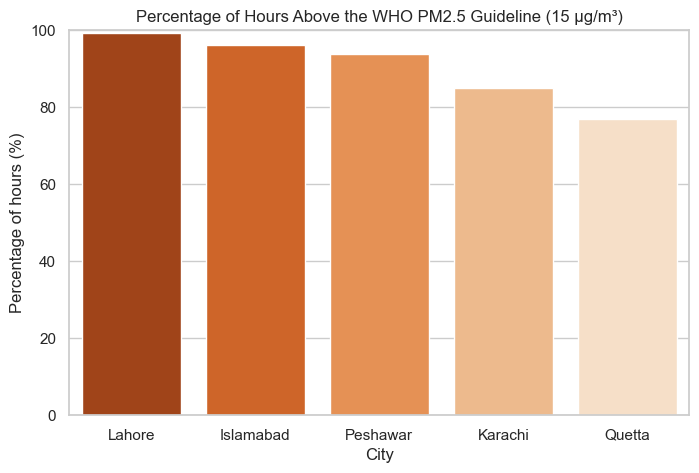

In [27]:
plt.figure(figsize=(8, 5))
above_sorted = above_who.sort_values(ascending=False)
sns.barplot(x=above_sorted.index, y=above_sorted.values, hue=above_sorted.index, palette='Oranges_r', legend=False)

plt.title('Percentage of Hours Above the WHO PM2.5 Guideline (15 µg/m³)')
plt.xlabel('City')
plt.ylabel('Percentage of hours (%)')
plt.ylim(0, 100)
plt.show()

**Answer:** In **every city** PM2.5 is above the WHO guideline most of the time. Lahore is above it in about **99% of hours**, Islamabad 96%, Peshawar 94% and Karachi 85%. Even in the cleanest city, Quetta, it is above the guideline in about **77% of hours**.

### Q10. Which variables are most related to PM2.5?

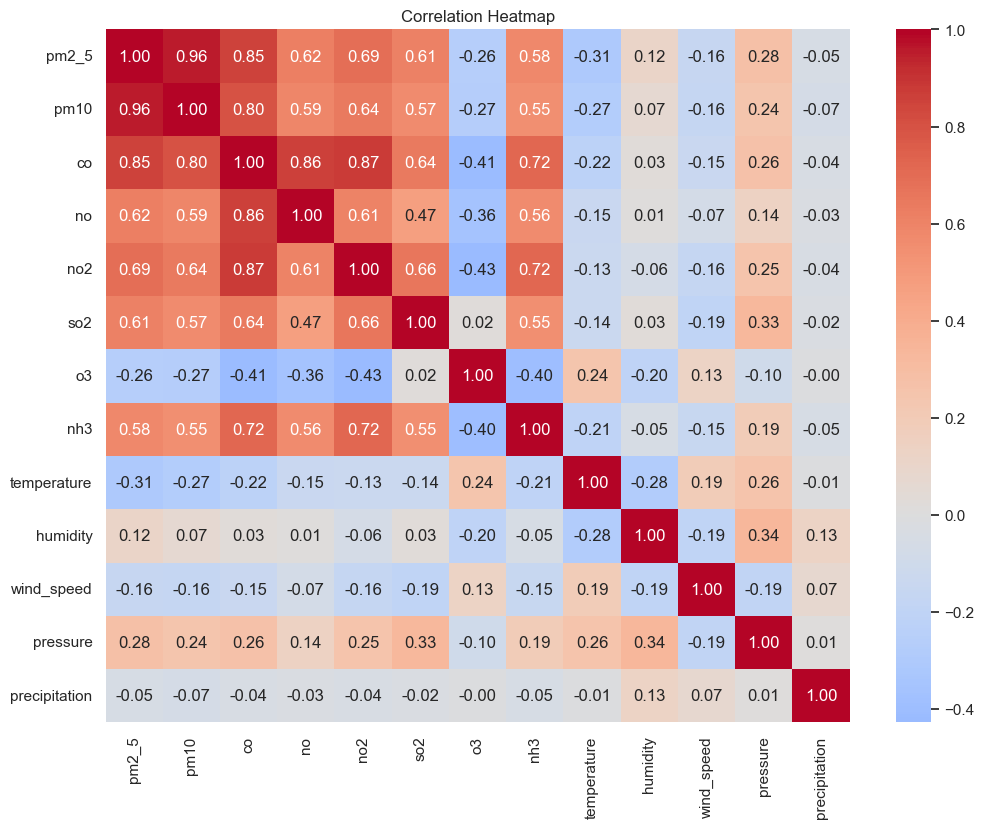

In [28]:
# Select the main pollutant and weather columns
cols = ['pm2_5', 'pm10', 'co', 'no', 'no2', 'so2', 'o3', 'nh3',
        'temperature', 'humidity', 'wind_speed', 'pressure', 'precipitation']

corr_matrix = df[cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)

plt.title('Correlation Heatmap')
plt.show()

In [29]:
# Correlation of every variable with PM2.5
corr_matrix['pm2_5'].drop('pm2_5').sort_values(ascending=False).round(2)

pm10             0.96
co               0.85
no2              0.69
no               0.62
so2              0.61
nh3              0.58
pressure         0.28
humidity         0.12
precipitation   -0.05
wind_speed      -0.16
o3              -0.26
temperature     -0.31
Name: pm2_5, dtype: float64

**Answer:**

- **Strong positive relationship:** PM10 (0.96), CO (0.85), NO2 (0.69), NO (0.62), SO2 (0.61) and NH3 (0.58). When these go up, PM2.5 usually goes up too, which points to common sources such as traffic, industry and burning.
- **Weak or negative relationship:** temperature (-0.31), ozone (-0.26) and wind speed (-0.16). Warmer and windier hours tend to have less PM2.5.
- Rainfall has almost no relationship (-0.05) in this dataset.

*Remember:* correlation does not prove that one variable causes the other.

### Q11. Does wind speed reduce PM2.5?

In [30]:
# Split wind speed into 4 equal-sized groups
df['wind_group'] = pd.qcut(df['wind_speed'], 4, labels=['Low', 'Medium-Low', 'Medium-High', 'High'])

wind_pm25 = df.groupby('wind_group')['pm2_5'].mean()
wind_pm25.round(1)

wind_group
Low            137.4
Medium-Low     119.3
Medium-High    115.1
High            80.3
Name: pm2_5, dtype: float64

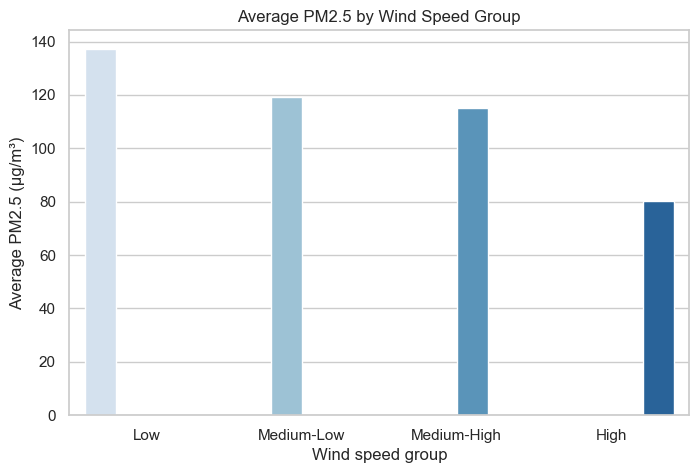

In [31]:
plt.figure(figsize=(8, 5))
sns.barplot(x=wind_pm25.index, y=wind_pm25.values, hue=wind_pm25.index, palette='Blues', legend=False)

plt.title('Average PM2.5 by Wind Speed Group')
plt.xlabel('Wind speed group')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.show()

**Answer:** Yes, there is a clear pattern. Hours with the **strongest winds (top 25%) have an average PM2.5 of 80 µg/m³**, compared with **137 µg/m³ when the wind is weakest**. Wind helps to spread pollution; calm weather lets it build up.

## 8. Machine Learning: Predicting PM2.5

**Goal:** Build models that predict the PM2.5 value of an hour.

**Metrics used:**
- **MAE** (Mean Absolute Error): the average size of the error, in µg/m³. Lower is better.
- **RMSE** (Root Mean Squared Error): like MAE but gives more weight to big mistakes. Lower is better.
- **R² score**: the share of the variation in PM2.5 that the model explains. 1.0 is perfect, 0 is no better than guessing the average.

**Models used:**
- **Baseline:** always predicts the average PM2.5. A useful model must beat this.
- **Linear Regression:** a simple model that fits a straight-line relationship.
- **Random Forest:** many decision trees working together; it can learn non-linear patterns.

### Q12. Can we predict PM2.5, and which model works best?

We run **three experiments** so that the results are honest:

| Experiment | Features used | Data split |
|-----------|---------------|-----------|
| **A** | Everything (pollutants + AQI + weather + time + city) | Random 80/20 |
| **B** | Only weather + time + city (no pollutants, no AQI) | Random 80/20 |
| **C** | Same as B | Train on 2021-2023, test on 2024 |

*Why?* In Experiment A, PM10, CO and AQI are measured at the same time as PM2.5, and AQI is partly calculated from PM2.5 itself. That makes the task easy. Experiments B and C ask a harder and more realistic question: **how much of PM2.5 can be explained by weather, season, time and place alone?**

In [32]:
# A small helper to calculate the three scores
def get_scores(name, y_true, y_pred):
    return {
        'Model': name,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2 Score': r2_score(y_true, y_pred)
    }

results = []   # we will store the scores of every model here

### Experiment A: All Features

In [33]:
# Target and features
y = df['pm2_5']
X_a = df.drop(columns=['pm2_5', 'datetime', 'wind_group'])

# Convert city and season to numbers (one-hot encoding)
X_a = pd.get_dummies(X_a, columns=['city', 'season'], drop_first=True)

print("Feature matrix shape:", X_a.shape)
X_a.head()

Feature matrix shape: (141201, 28)


,aqi,co,no,no2,o3,so2,pm10,nh3,temperature,humidity,...,hour,day_of_week,is_weekend,city_Karachi,city_Lahore,city_Peshawar,city_Quetta,season_Spring,season_Summer,season_Winter
0,5,1014.71,0.00,17.14,35.76,6.44,66.81,5.95,28.1,80.0,...,0,1,0,False,True,False,False,False,True,False
1,5,1054.76,0.01,19.36,32.19,6.68,74.88,6.08,27.8,83.0,...,1,1,0,False,True,False,False,False,True,False
2,5,1295.09,1.40,30.16,22.89,8.70,89.90,7.73,27.4,87.0,...,2,1,0,False,True,False,False,False,True,False
3,5,1682.28,9.16,41.13,28.25,12.99,111.25,9.75,27.1,89.0,...,3,1,0,False,True,False,False,False,True,False
4,5,1321.79,4.81,32.56,91.55,27.90,97.95,7.28,26.9,91.0,...,4,1,0,False,True,False,False,False,True,False


We split the data into **80% training** and **20% testing**. The model learns from the training part and is judged on the testing part, which it has never seen.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X_a, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (112960, 28)
Testing set : (28241, 28)


**Baseline model**

In [35]:
# Baseline: always predicts the average PM2.5
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)

results.append(get_scores('Baseline (average)', y_test, baseline.predict(X_test)))
results[-1]

{'Model': 'Baseline (average)',
 'MAE': 96.67724774621094,
 'RMSE': np.float64(145.13645710436663),
 'R2 Score': -2.6381815982912116e-06}

The baseline has an R² of about 0 and an average error of about 97 µg/m³. Every real model must do better than this.

**Linear Regression**

In [36]:
lr_a = LinearRegression()
lr_a.fit(X_train, y_train)

y_pred_lr_a = lr_a.predict(X_test)

results.append(get_scores('A: Linear Regression', y_test, y_pred_lr_a))
results[-1]

{'Model': 'A: Linear Regression',
 'MAE': 15.134715078549066,
 'RMSE': np.float64(23.629706386281512),
 'R2 Score': 0.9734927446646263}

**Random Forest**

In [37]:
rf_a = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_a.fit(X_train, y_train)

y_pred_rf_a = rf_a.predict(X_test)

results.append(get_scores('A: Random Forest', y_test, y_pred_rf_a))
results[-1]

{'Model': 'A: Random Forest',
 'MAE': 5.016832597995823,
 'RMSE': np.float64(9.52530323358023),
 'R2 Score': 0.9956926939488749}

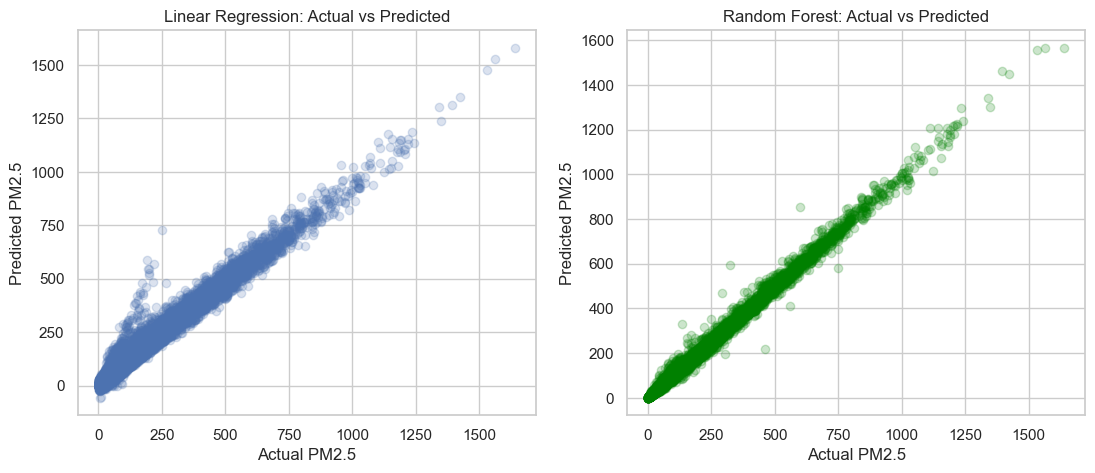

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred_lr_a, alpha=0.2)
axes[0].set_title('Linear Regression: Actual vs Predicted')

axes[1].scatter(y_test, y_pred_rf_a, alpha=0.2, color='green')
axes[1].set_title('Random Forest: Actual vs Predicted')

for ax in axes:
    ax.set_xlabel('Actual PM2.5')
    ax.set_ylabel('Predicted PM2.5')

plt.show()

**Answer (Experiment A):** Both models are very accurate. Linear Regression gives R² = 0.973 (average error about 15 µg/m³) and **Random Forest is the best with R² = 0.996 (average error about 5 µg/m³)**. The points of the Random Forest plot lie almost exactly on a straight line.

However, this high accuracy is mainly because the model can use PM10 and AQI, which are almost the same information as PM2.5. This is the next question.

### Q13. Which features matter most for prediction?

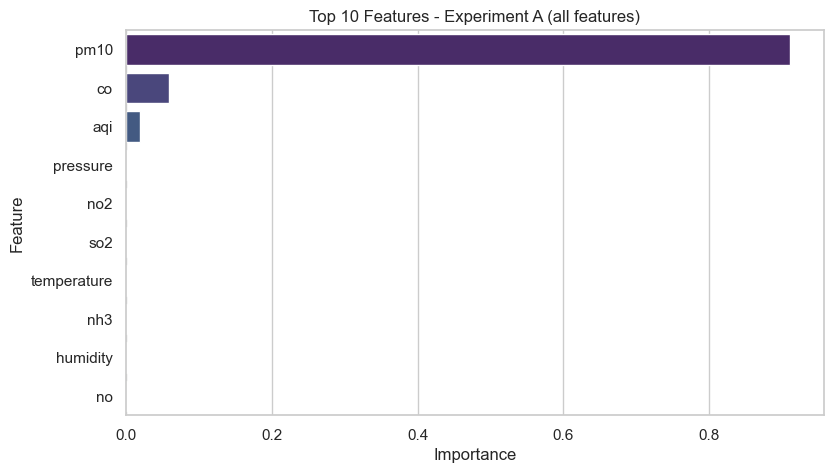

,Feature,Importance
6,pm10,0.9117
1,co,0.0584
0,aqi,0.0186
12,pressure,0.0016
3,no2,0.0012
5,so2,0.0012
8,temperature,0.0010
7,nh3,0.0009
9,humidity,0.0008
2,no,0.0008


In [39]:
imp_a = pd.DataFrame({'Feature': X_a.columns, 'Importance': rf_a.feature_importances_})
imp_a = imp_a.sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=imp_a, x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)

plt.title('Top 10 Features - Experiment A (all features)')
plt.show()

imp_a.round(4)

**Answer (Experiment A):** **PM10 alone has an importance of 0.91**, followed by CO (0.06) and AQI (0.02). So the model is mostly "reading" PM2.5 from PM10. This is useful for estimating PM2.5 when a sensor is missing, but it does not show that weather or season can predict pollution. Experiments B and C test this.

### Experiment B: Weather, Time and City Only

In [40]:
# Remove AQI and all pollutant columns, keep only weather, time and city
pollutant_cols = ['aqi', 'co', 'no', 'no2', 'o3', 'so2', 'pm10', 'nh3']

X_b = df.drop(columns=['pm2_5', 'datetime', 'wind_group'] + pollutant_cols)
X_b = pd.get_dummies(X_b, columns=['city', 'season'], drop_first=True)

print("Feature matrix shape:", X_b.shape)
print(X_b.columns.tolist())

Feature matrix shape: (141201, 20)
['temperature', 'humidity', 'dew_point', 'precipitation', 'pressure', 'wind_speed', 'wind_direction', 'solar_radiation', 'year', 'month', 'hour', 'day_of_week', 'is_weekend', 'city_Karachi', 'city_Lahore', 'city_Peshawar', 'city_Quetta', 'season_Spring', 'season_Summer', 'season_Winter']


In [41]:
# Same random split as before (same random_state), so the comparison is fair
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_b, y, test_size=0.2, random_state=42)

In [42]:
lr_b = LinearRegression()
lr_b.fit(Xb_train, yb_train)

results.append(get_scores('B: Linear Regression', yb_test, lr_b.predict(Xb_test)))
results[-1]

{'Model': 'B: Linear Regression',
 'MAE': 71.26361447233205,
 'RMSE': np.float64(111.44402568182504),
 'R2 Score': 0.41039427163921727}

In [43]:
rf_b = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_b.fit(Xb_train, yb_train)

y_pred_rf_b = rf_b.predict(Xb_test)

results.append(get_scores('B: Random Forest', yb_test, y_pred_rf_b))
results[-1]

{'Model': 'B: Random Forest',
 'MAE': 31.605476495166602,
 'RMSE': np.float64(62.373860257690275),
 'R2 Score': 0.815305757710029}

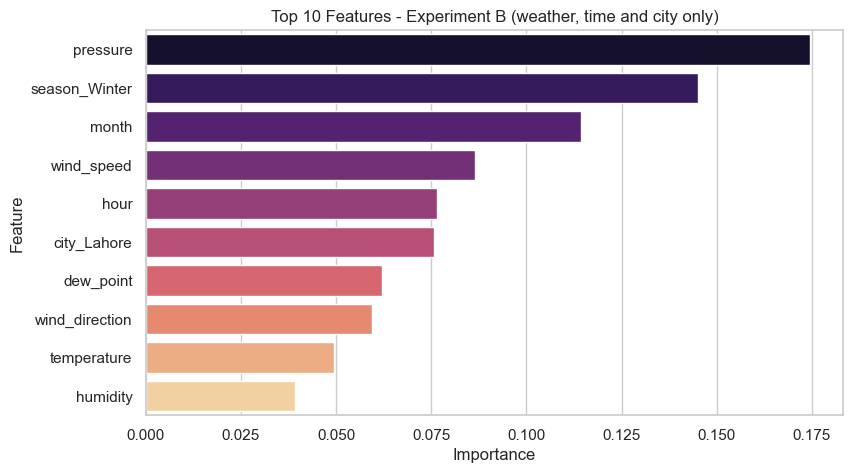

,Feature,Importance
4,pressure,0.1745
19,season_Winter,0.1450
9,month,0.1144
5,wind_speed,0.0865
10,hour,0.0765
14,city_Lahore,0.0757
2,dew_point,0.0621
6,wind_direction,0.0593
0,temperature,0.0495
1,humidity,0.0392


In [44]:
imp_b = pd.DataFrame({'Feature': X_b.columns, 'Importance': rf_b.feature_importances_})
imp_b = imp_b.sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=imp_b, x='Importance', y='Feature', hue='Feature', palette='magma', legend=False)

plt.title('Top 10 Features - Experiment B (weather, time and city only)')
plt.show()

imp_b.round(4)

**Answer (Experiment B):** Without any pollutant information the scores drop, but the models are still useful:

- Linear Regression: R² = 0.41
- **Random Forest: R² = 0.82** (average error about 32 µg/m³)

Random Forest is much better than Linear Regression here, which shows that the link between weather and pollution is **non-linear**. The most important features are **air pressure, winter season, month, wind speed, hour of the day and being in Lahore**. This matches what we saw in the EDA: pollution depends on season, wind and time of day.

### Q14. How well does the model work on future data it has never seen?

In Experiment B the test hours are mixed randomly with the training hours, so for many test hours the model has seen the hour just before and just after. Real forecasting is harder. In **Experiment C** we train on 2021 to 2023 and test on the whole of 2024.

In [45]:
# Train on 2021-2023, test on 2024 (the model never sees the future)
train_mask = df['year'] < 2024
test_mask = df['year'] == 2024

# 'year' is removed here because 2024 is a year the model has never seen
X_c = X_b.drop(columns=['year'])

rf_c = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_c.fit(X_c[train_mask], y[train_mask])

y_pred_c = rf_c.predict(X_c[test_mask])

results.append(get_scores('C: Random Forest (train 2021-23, test 2024)', y[test_mask], y_pred_c))
results[-1]

{'Model': 'C: Random Forest (train 2021-23, test 2024)',
 'MAE': 53.934691295556796,
 'RMSE': np.float64(102.02390270162408),
 'R2 Score': 0.4243367054761603}

**Answer (Experiment C):** On completely unseen future data the Random Forest reaches **R² = 0.42** with an average error of about 54 µg/m³. This is still much better than the baseline (R² of 0), but clearly worse than the 0.82 from the random split. **The honest accuracy of predicting from weather and time alone is therefore moderate.** To improve it we would need information such as the previous hours' PM2.5 or emission data.

## 9. Model Comparison

In [46]:
# Compare all models
comparison = pd.DataFrame(results).round(3)
comparison

,Model,MAE,RMSE,R2 Score
0,Baseline (average),96.677,145.136,-0.000
1,A: Linear Regression,15.135,23.630,0.973
2,A: Random Forest,5.017,9.525,0.996
3,B: Linear Regression,71.264,111.444,0.410
4,B: Random Forest,31.605,62.374,0.815
5,"C: Random Forest (train 2021-23, test 2024)",53.935,102.024,0.424


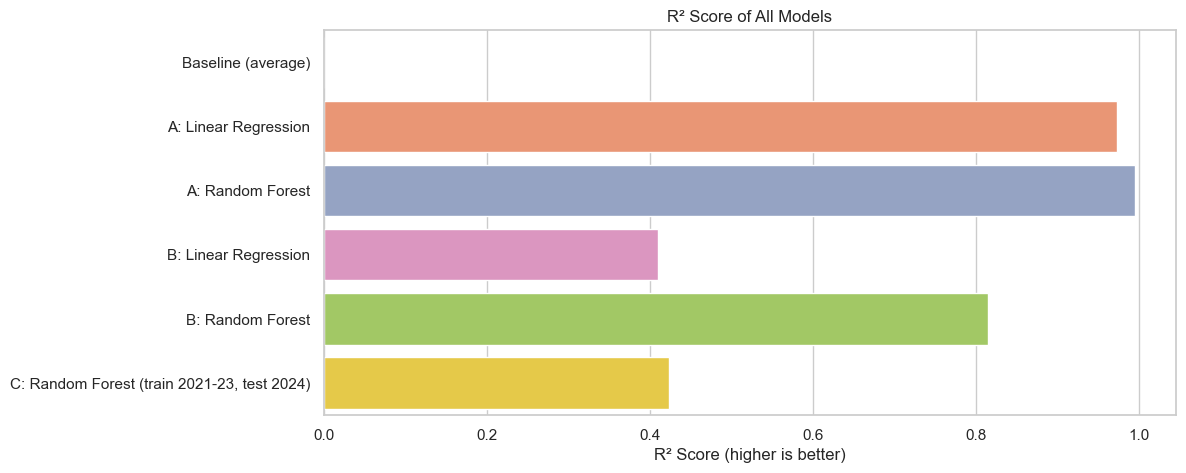

In [47]:
plt.figure(figsize=(11, 5))
sns.barplot(data=comparison, y='Model', x='R2 Score', hue='Model', palette='Set2', legend=False)

plt.title('R² Score of All Models')
plt.xlabel('R² Score (higher is better)')
plt.ylabel('')
plt.show()

| Experiment | Best model | R² | What it tells us |
|-----------|-----------|----|------------------|
| A: all features | Random Forest | 0.996 | PM2.5 can be estimated almost perfectly from other pollutants (mainly PM10) |
| B: weather + time + city (random split) | Random Forest | 0.815 | Weather and season explain a large part of PM2.5 |
| C: weather + time + city (train 2021-23, test 2024) | Random Forest | 0.424 | Honest accuracy on future data is moderate |

In all three experiments **Random Forest clearly beat Linear Regression and the baseline**.

## 10. Key Findings

1. **Lahore is the most polluted city** (average PM2.5 about 199 µg/m³, AQI at the worst level in about 78% of hours). **Quetta is the cleanest** (about 33 µg/m³).
2. The differences between cities are **statistically significant** (Kruskal-Wallis test).
3. **Winter is the worst season** (average 217 µg/m³), with the peak in **December and January**; Lahore reaches about 381 µg/m³ in winter. Summer is the cleanest season.
4. PM2.5 follows a **daily cycle**: lowest around 9:00 and highest around 18:00.
5. PM2.5 is above the **WHO guideline of 15 µg/m³** in most hours in all five cities (77% to 99% of hours).
6. PM2.5 is strongly linked with **PM10 (0.96) and CO (0.85)** and negatively with **temperature and wind speed**. Windy hours have about 40% less PM2.5 than calm hours.
7. A **Random Forest** gave the best predictions in every experiment (R² = 0.996 with all features, 0.82 with weather/time only, 0.42 on unseen 2024 data).
8. Predictions look very accurate when PM10 is available, but **honest forecasting from weather and time alone is only moderate**.

## 11. Limitations

- The dataset covers only about **3.3 years**, and 2021 and 2024 are incomplete, so long-term trends cannot be confirmed.
- Each city has **one set of readings**, which may not represent the whole city.
- The AQI is on a simple 1 to 5 scale, so it hides detail compared with the PM2.5 values.
- The WHO comparison uses hourly values against a 24-hour guideline, so it is approximate.
- Correlation does not mean causation.
- Models in Experiments A and B use a random split on time-series data, which makes the scores look better than real forecasting (see Experiment C).

## 12. Future Work

- Add **lag features** (PM2.5 of the previous hours) and test models such as XGBoost or LSTM.
- Add more cities, more years and information about traffic, industry and crop burning.
- Predict the AQI category (classification) and build a simple dashboard.
- Use hyperparameter tuning and cross-validation.

## 13. Conclusion

This project analysed hourly air quality and weather data from five Pakistani cities. Air pollution is a serious problem, especially in **Lahore, Peshawar and Islamabad during winter**, and PM2.5 stays above the WHO guideline most of the time in all cities. Pollution is strongly related to other pollutants (PM10, CO), and is lower on windy and warm days.

Random Forest predicted PM2.5 best. Using all pollutant data it reached an R² of 0.996, but when only weather, time and city were used, the accuracy dropped to 0.82 on random test data and 0.42 on unseen future data. This shows how important it is to **test models honestly**, and it gives a clear direction for future improvement.

